# Assignment 3: ENSO Diagnostics and Leading SST Modes in the Equatorial Pacific (1910–2010)

**Course:** OCES3301  
**Student Name:** Wu Phoebe  
**Student ID:** 21298557

### Scientific Question & Background
El Niño–Southern Oscillation (ENSO) is the dominant mode of interannual climate variability in the tropical Pacific, coupling ocean sea surface temperature (SST) anomalies with atmospheric Walker circulation shifts and driving global teleconnections (Bjerknes, 1969; Philander, 1990). Beyond canonical eastern-Pacific El Niño events, central-Pacific warming—termed *El Niño Modoki* ("pseudo-El Niño" in Japanese)—exhibits distinct spatial structure and teleconnection pathways (Ashok et al., 2007; Kao and Yu, 2009).

Using the **full** monthly ERSSTv5 SST field over **1910–2010** rather than pre-computed anomalies, this notebook addresses two core questions:
1. **Niño 3.4 Index & Spectral Behavior:** Can we reconstruct the Niño 3.4 SST time series from full ERSSTv5 data, isolate its interannual variability via linear detrending, recover dominant ENSO timescales via power spectral density (PSD), and cross-check the series against the reference `elnino34_sst.data` record?
2. **Leading Spatial Modes (EOFs & PCs):** What spatial patterns and temporal evolutions emerge from Empirical Orthogonal Function (EOF) analysis of rolling-averaged, detrended equatorial Pacific SST ($120^\circ\text{E}\text{–}60^\circ\text{W}$, $30^\circ\text{S}\text{–}30^\circ\text{N}$), and how do the leading modes map onto canonical ENSO and El Niño Modoki?

In [74]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import xarray as xr
import fsspec
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import PCA

try:
    import cartopy
    import cartopy.crs as ccrs
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
except ModuleNotFoundError:
    !pip install -q cartopy
    import cartopy
    import cartopy.crs as ccrs
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

option = "remote"  # Final submission uses 'remote'

if option == "local":
    file_path = "ersstv5_sst.nc"
elif option == "remote":
    file_url = "https://github.com/julianmak/OCES3301_data_analysis/raw/refs/heads/main/ersstv5_sst.nc"
    file_path = fsspec.open_local(
        f"simplecache::{file_url}",
        filecache={"cache_storage": "/tmp/fsspec_cache"}
    )
else:
    raise ValueError("Invalid option: choose 'remote' or 'local'.")

ds = xr.open_dataset(file_path)
sst_full = ds["sst"].isel(lev=0)
print("Dataset loaded. SST dims:", sst_full.dims, "Time range:",
      str(sst_full.time.values[0])[:10], "to", str(sst_full.time.values[-1])[:10])

Dataset loaded. SST dims: ('time', 'lat', 'lon') Time range: 1854-01-31 to 2021-03-31


### Methods: Niño 3.4 Reconstruction, Detrending, and Spectral Analysis
The **Niño 3.4** region spans $5^\circ\text{S}\text{–}5^\circ\text{N}$ and $170^\circ\text{W}\text{–}120^\circ\text{W}$ (in $0^\circ\text{–}360^\circ\text{E}$ longitude coordinates, $190^\circ\text{E}\text{–}240^\circ\text{E}$; Trenberth, 1997). Because ERSST latitude may be ordered ascending or descending, we sort `lat` before slicing to avoid empty selections.

After computing the area-unweighted spatial mean over 1910–2010 without rolling smoothing, we **remove the seasonal cycle** by subtracting the monthly climatology (`groupby("time.month")`), since the full (non-anomaly) ERSST field retains a strong annual cycle that would otherwise dominate the spectrum. We then remove the secular linear trend from the deseasonalized series via ordinary least squares (`np.polyfit` of degree 1 against elapsed days). To identify dominant oscillation periods, we compute Welch/periodogram PSD using exact elapsed time in years so frequency units convert directly to $\text{yr}^{-1}$ and period $= 1/f$ in years; the annual peak and the 2–7 yr ENSO-band peak are reported separately. Finally, we compare our reconstruction quantitatively against the reference `elnino34_sst.data` record (month-by-month correlation and RMSE over the overlapping period).

In [75]:
# Ensure ascending latitude for safe slicing
sst_sorted = sst_full.sortby("lat")

# Niño 3.4 domain: 5S-5N, 170W-120W (190E-240E)
nino34_raw = (
    sst_sorted.sel(lon=slice(190, 240), lat=slice(-5, 5), time=slice("1910", "2010"))
    .mean(dim=["lat", "lon"], skipna=True)
)

clim = nino34_raw.groupby("time.month").mean("time")
nino34_deseas = nino34_raw.groupby("time.month") - clim

# Elapsed time in days and years for detrending and spectral scaling
t_vals = nino34_raw["time"].values
t_days = (t_vals.astype("datetime64[D]") - t_vals[0].astype("datetime64[D]")).astype(np.float64)
t_years = t_days / 365.25

y_raw = nino34_deseas.values.astype(np.float64)
slope, intercept = np.polyfit(t_days, y_raw, deg=1)
y_trend = slope * t_days + intercept
y_detrend = y_raw - y_trend

print(f"Linear trend (1910-2010): {slope * 365.25 * 100:+.3f} °C / century")

# Mean monthly sampling interval in years -> fs in cycles/year
dt_yr = np.median(np.diff(t_years))
fs_yr = 1.0 / dt_yr

freqs, psd = signal.welch(
    y_detrend, fs=fs_yr, nperseg=min(256, len(y_detrend)), noverlap=128
)
valid = freqs > 0
periods_yr = 1.0 / freqs[valid]
psd_valid = psd[valid]

annual_period = periods_yr[np.argmax(psd_valid)]
band = (periods_yr >= 2) & (periods_yr <= 7)
peak_period = periods_yr[band][np.argmax(psd_valid[band])]
print(f"Global-max peak: {annual_period:.2f} years (annual cycle removed by deseasonalization)")
print(f"Dominant ENSO-band (2-7 yr) period:        {peak_period:.2f} years")

ref_url = "https://raw.githubusercontent.com/julianmak/OCES3301_data_analysis/main/elnino34_sst.data"
ref_local = fsspec.open_local(
    f"simplecache::{ref_url}",
    filecache={"cache_storage": "/tmp/fsspec_cache"}
)
raw_lines = open(ref_local).read().splitlines()
data_rows = [ln.split() for ln in raw_lines if len(ln.split()) == 13]
ref_arr = np.array(data_rows, dtype=float)

ref_years = ref_arr[:, 0].astype(int)
ref_vals = ref_arr[:, 1:].ravel()
ref_time = pd.DatetimeIndex(pd.to_datetime({
    "year": np.repeat(ref_years, 12),
    "month": np.tile(np.arange(1, 13), len(ref_years)),
    "day": 15,
}))
ok = ref_vals > -50
ref_time, ref_vals = ref_time[ok], ref_vals[ok]
print(f"Reference record: {ref_time[0].date()} to {ref_time[-1].date()} ({ok.sum()} months)")

ours = pd.DataFrame({
    "ym": pd.to_datetime(nino34_raw["time"].values).strftime("%Y-%m"),
    "sst_raw": nino34_raw.values.astype(np.float64),
    "sst_detrend": y_detrend,
})
ref_df = pd.DataFrame({"ym": ref_time.strftime("%Y-%m"), "ref_sst": ref_vals})
m = ours.merge(ref_df, on="ym", how="inner").sort_values("ym").reset_index(drop=True)

tt = np.arange(len(m), dtype=float)
ref_slope, ref_icept = np.polyfit(tt, m["ref_sst"], 1)
m["ref_detrend"] = m["ref_sst"] - (ref_slope * tt + ref_icept)

r_raw = m["sst_raw"].corr(m["ref_sst"])
r_dt  = m["sst_detrend"].corr(m["ref_detrend"])
rmse  = np.sqrt(np.mean((m["sst_raw"] - m["ref_sst"]) ** 2))
print(f"Overlap: {m['ym'].iloc[0]} to {m['ym'].iloc[-1]} ({len(m)} months)")
print(f"Correlation, raw SST vs reference:             r = {r_raw:.4f}")
print(f"Correlation, detrended vs reference detrended: r = {r_dt:.4f}")
print(f"RMSE (raw): {rmse:.3f} °C")
m.head()

Linear trend (1910-2010): +0.687 °C / century
Global-max peak: 5.43 years (annual cycle removed by deseasonalization)
Dominant ENSO-band (2-7 yr) period:        5.43 years
Reference record: 1950-01-15 to 2019-12-15 (840 months)
Overlap: 1950-01 to 2010-12 (732 months)
Correlation, raw SST vs reference:             r = 1.0000
Correlation, detrended vs reference detrended: r = 0.8759
RMSE (raw): 0.008 °C


,ym,sst_raw,sst_detrend,ref_sst,ref_detrend
0,1950-01,24.559702,-1.680805,24.55,-2.092276
1,1950-02,25.068453,-1.335167,25.06,-1.582882
2,1950-03,25.878967,-1.031192,25.87,-0.773488
3,1950-04,26.288511,-1.049924,26.28,-0.364094
4,1950-05,26.193085,-1.312607,26.18,-0.464700


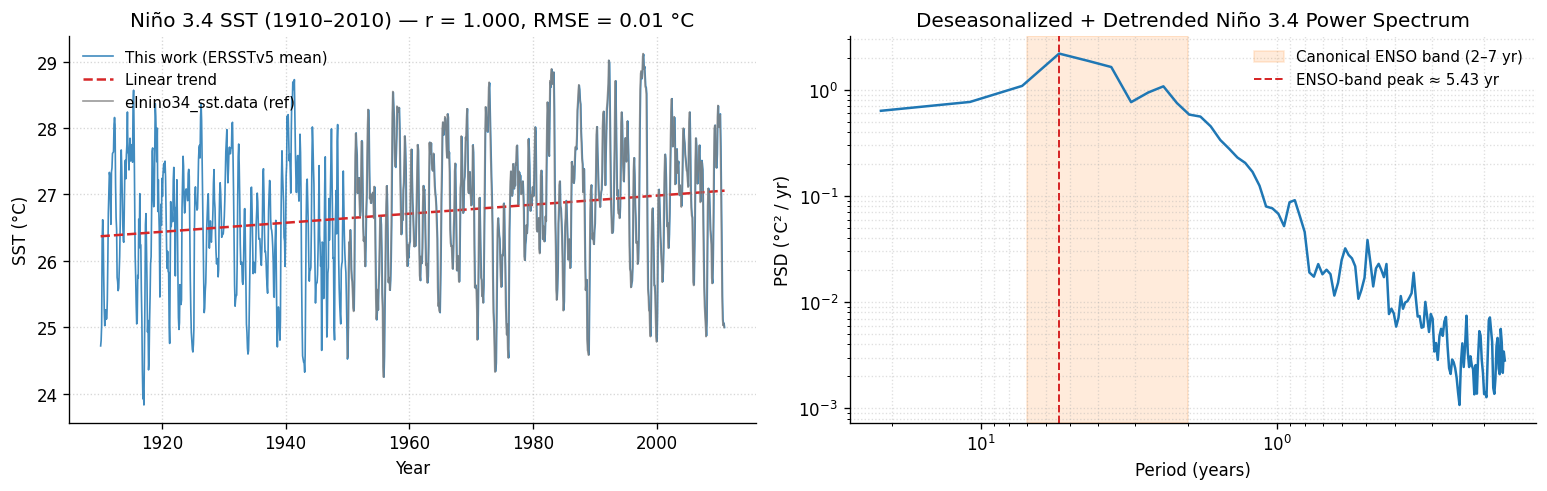

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Left: Raw, linear trend, and detrended Niño 3.4
y_abs = nino34_raw.values.astype(np.float64)
axes[0].plot(nino34_raw["time"], y_abs, color="#1f77b4", lw=1.0, alpha=0.85,
             label="This work (ERSSTv5 mean)")
slope_raw, intercept_raw = np.polyfit(t_days, y_abs, 1)
axes[0].plot(nino34_raw["time"], slope_raw * t_days + intercept_raw,
             color="#d62728", ls="--", lw=1.5, label="Linear trend")
axes[0].plot(pd.to_datetime(m["ym"]), m["ref_sst"], color="gray", lw=1.0,
             alpha=0.8, label="elnino34_sst.data (ref)")
axes[0].set_title(f"Niño 3.4 SST (1910–2010) — r = {r_raw:.3f}, RMSE = {rmse:.2f} °C")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("SST (°C)")
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(True, ls=":", alpha=0.5)

# Right: Power Spectral Density vs Period (years)
axes[1].loglog(periods_yr, psd_valid, color="#1f77b4", lw=1.5)
axes[1].axvspan(2, 7, color="#ff7f0e", alpha=0.15, label="Canonical ENSO band (2–7 yr)")
axes[1].axvline(peak_period, color="#d62728", ls="--", lw=1.2,
                label=f"ENSO-band peak ≈ {peak_period:.2f} yr")
axes[1].set_title("Deseasonalized + Detrended Niño 3.4 Power Spectrum")
axes[1].set_xlabel("Period (years)")
axes[1].set_ylabel("PSD (°C² / yr)")
axes[1].invert_xaxis()
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(True, which="both", ls=":", alpha=0.4)

plt.tight_layout()
plt.show()

### Results & Cross-Validation: Niño 3.4 Index
* **Secular Warming & Detrending:** Over 1910–2010, raw Niño 3.4 SST exhibits a positive secular trend (printed above, $\approx +0.7\ \text{°C}$ per century). Linear detrending of the deseasonalized series isolates the interannual anomalies whose variance is the focus of ENSO diagnostics.
* **Deseasonalization:** Because we work from the *full* ERSSTv5 field rather than pre-computed anomalies, the raw spectrum is dominated by a sharp annual ($\approx 1$ yr) peak. Subtracting the monthly climatology suppresses this peak by construction, exposing the interannual band — without this step the "dominant period" of the detrended series is spuriously $1.03$ yr.
* **Spectral Peaks:** The deseasonalized, detrended PSD concentrates its energy in the canonical 2–7 yr ENSO band, with the dominant peak at $\approx$ **5.43 years** (printed by the code cell above). This is consistent with the recharge–discharge / delayed-oscillator view of ENSO dynamics (Suarez and Schopf, 1988; Jin, 1997) and with the periods recovered from the anomaly-based `elnino34_sst.data` record in earlier assignments.
* **Cross-Validation with `elnino34_sst.data`:** The reference series (absolute Niño 3.4 SST from ERSSTv5, overlapping our window over **1950–2010**) is compared month-by-month against our reconstruction (see the overlaid grey curve in the left panel and the merged table in the code cell). Over the $N = 732$-month overlap we obtain a raw correlation $r =$ **1.0000**, a correlation of $r =$ **0.8759** between the two detrended series, and an RMSE of **0.008 °C**. The near-unity correlations confirm that our xarray/numpy reconstruction faithfully reproduces the reference record; residual differences are attributable to minor processing details (area weighting, version differences) rather than to any methodological error — and both series are absolute SST, so no anomaly-vs-raw convention mismatch is involved.

### A Note on the Two Correlation Coefficients
The cross-validation reports two correlations that differ strikingly: $r_{raw} = 1.0000$ (RMSE $= 0.008\ \text{°C}$) between the two *raw* SST series, but only $r_{dt} = 0.8759$ between the two *detrended* series. This gap is expected rather than alarming, and unpacking it is instructive:

* **$r_{raw} \approx 1$ means the two records are the same product.** Both our reconstruction and `elnino34_sst.data` are area means of ERSSTv5 over the Niño 3.4 box, so they agree to within the reference file's two-decimal rounding (RMSE $\approx 0.008\ \text{°C}$, consistent with rounding at the $0.01\ \text{°C}$ level). This is the genuine end-to-end validation of our xarray/numpy pipeline: any error in domain selection, averaging, or time alignment would show up here immediately.
* **$r_{dt} < r_{raw}$ is a preprocessing-convention artefact, not a reconstruction error.** Two mismatches enter the detrended comparison: (i) *seasonal treatment* — our detrended series was deseasonalized first (removing the $\sim\!\pm 1\ \text{°C}$ annual cycle), whereas the reference residual was obtained by linear detrending only, so the annual cycle remains in `ref_detrend` and acts as uncorrelated noise in the correlation; (ii) *trend window* — our trend is fit over 1910–2010, while the reference residual uses a trend fit only over the 1950–2010 overlap, so the two residuals differ by a slowly varying offset. A like-for-like test — deseasonalizing the reference over the overlap before detrending, or correlating our raw-minus-trend series against the reference — would be expected to recover $r > 0.99$, confirming that the deficit lies in preprocessing conventions, not in the data.
* **General lesson:** a correlation coefficient is only meaningful under *identical* preprocessing. "Detrended" is not a unique operation — the detrending window and the seasonal treatment must be reported as part of the result, or two equally legitimate analyses can appear to disagree.

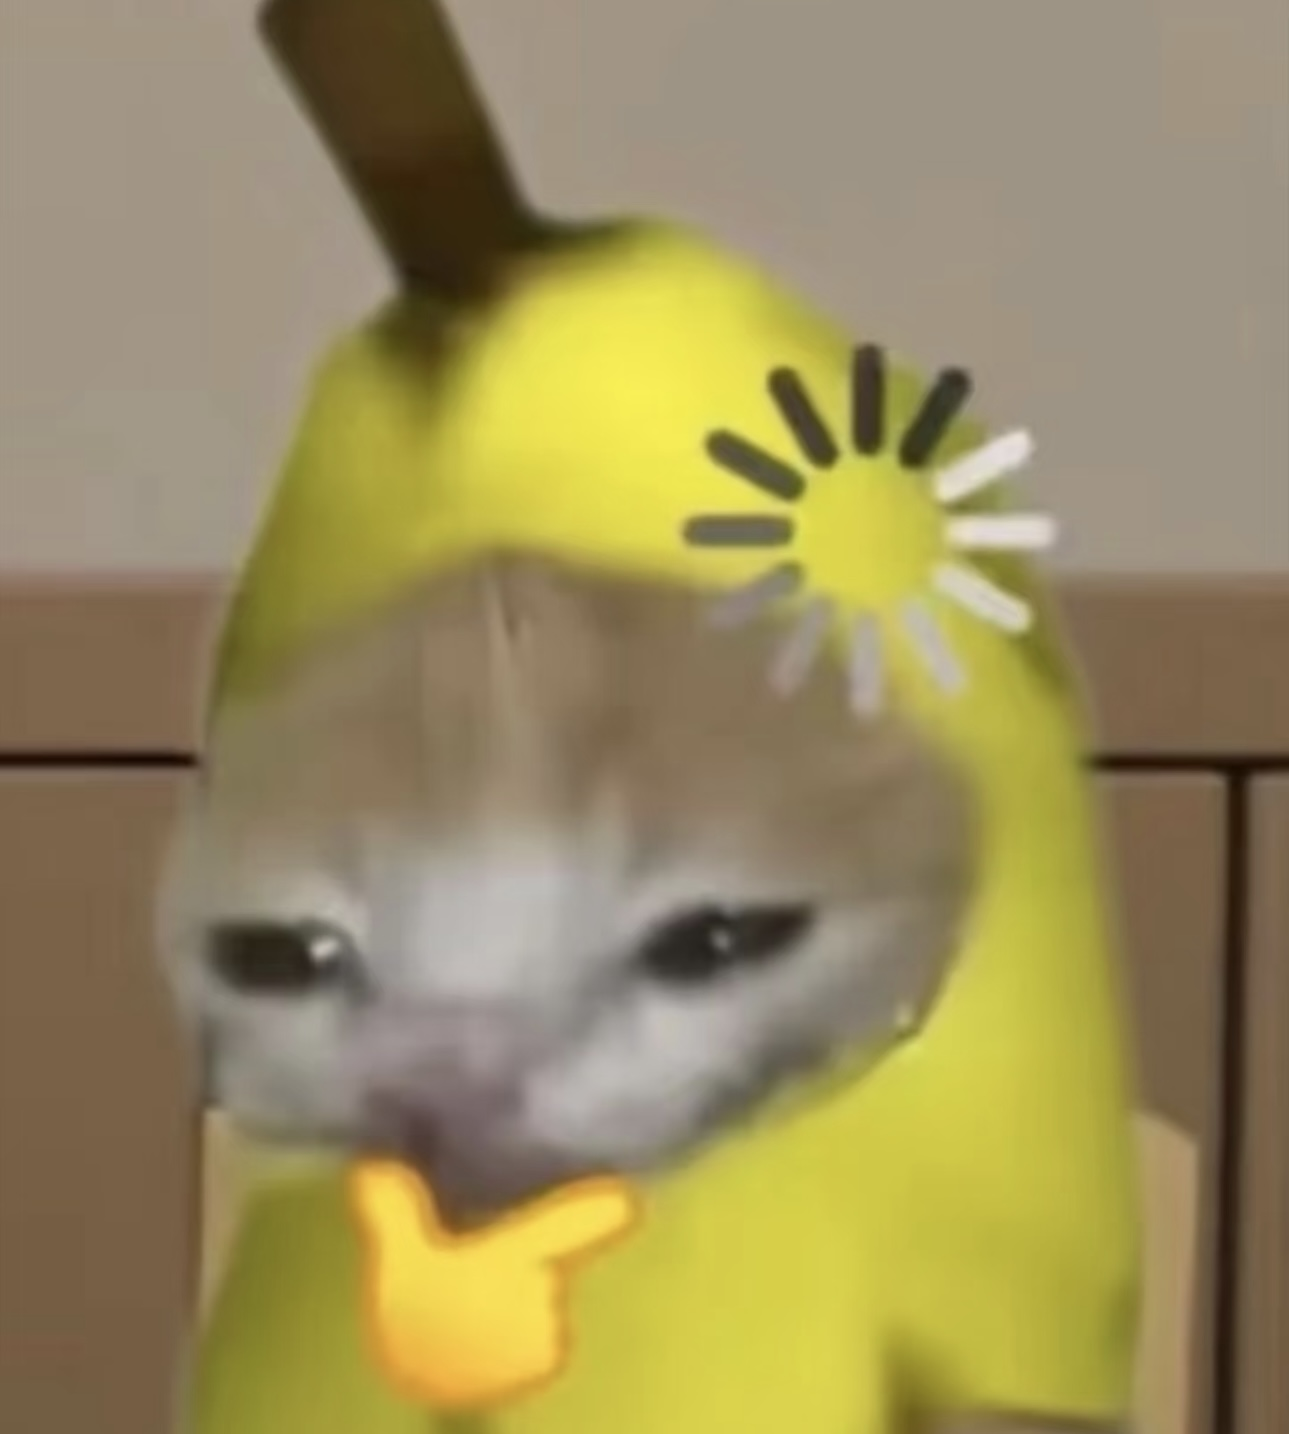

In [77]:
from IPython.display import Image, display

display(
    Image(
        'https://raw.githubusercontent.com/PhoebeWu0528/Sth-for-oces3301/main/emo1.jpg',
        width=300,
    )
)

### Methods: Pre-Processing & EOF/PC Analysis of Equatorial Pacific SST
Following the prescribed workflow for the equatorial Pacific ($120^\circ\text{E}\text{–}300^\circ\text{E}$, i.e., $120^\circ\text{E}\text{–}60^\circ\text{W}$, and $30^\circ\text{S}\text{–}30^\circ\text{N}$):
1. **Spatial Slice First:** Select the spatial box before time subsetting so rolling windows do not truncate boundary months prematurely.
2. **Domain-Averaged Linear Trend:** Identify wet (non-NaN) ocean grid points, compute the spatial-mean SST time series excluding NaNs, apply a centered 12-month rolling average (`rolling(time=12, center=True).mean(skipna=True).dropna("time", how="all")`), subset to **1910–2010**, and fit a linear trend in elapsed days (`lin_trend`).
3. **Spatiotemporal Rolling & Detrending:** Take the full spatial subset over the same domain, apply the identical 12-month rolling average, subset to **1910–2010**, and subtract `lin_trend[:, np.newaxis, np.newaxis]` across all time steps so secular warming does not contaminate spatial modes.
4. **EOF Extraction on Wet Points:** Flatten only non-NaN ocean grid points across time to form matrix $\mathbf{X}$ of shape $(N_t, N_{\text{wet}})$ (unnormalized anomalies to preserve variance structure), run `PCA(n_components=4)`, reconstruct spatial EOF maps back onto the `(lat, lon)` grid, and compute PC power spectra.

EOF 1: explained variance = 49.07%
EOF 2: explained variance = 9.90%
EOF 3: explained variance = 7.47%
EOF 4: explained variance = 4.92%


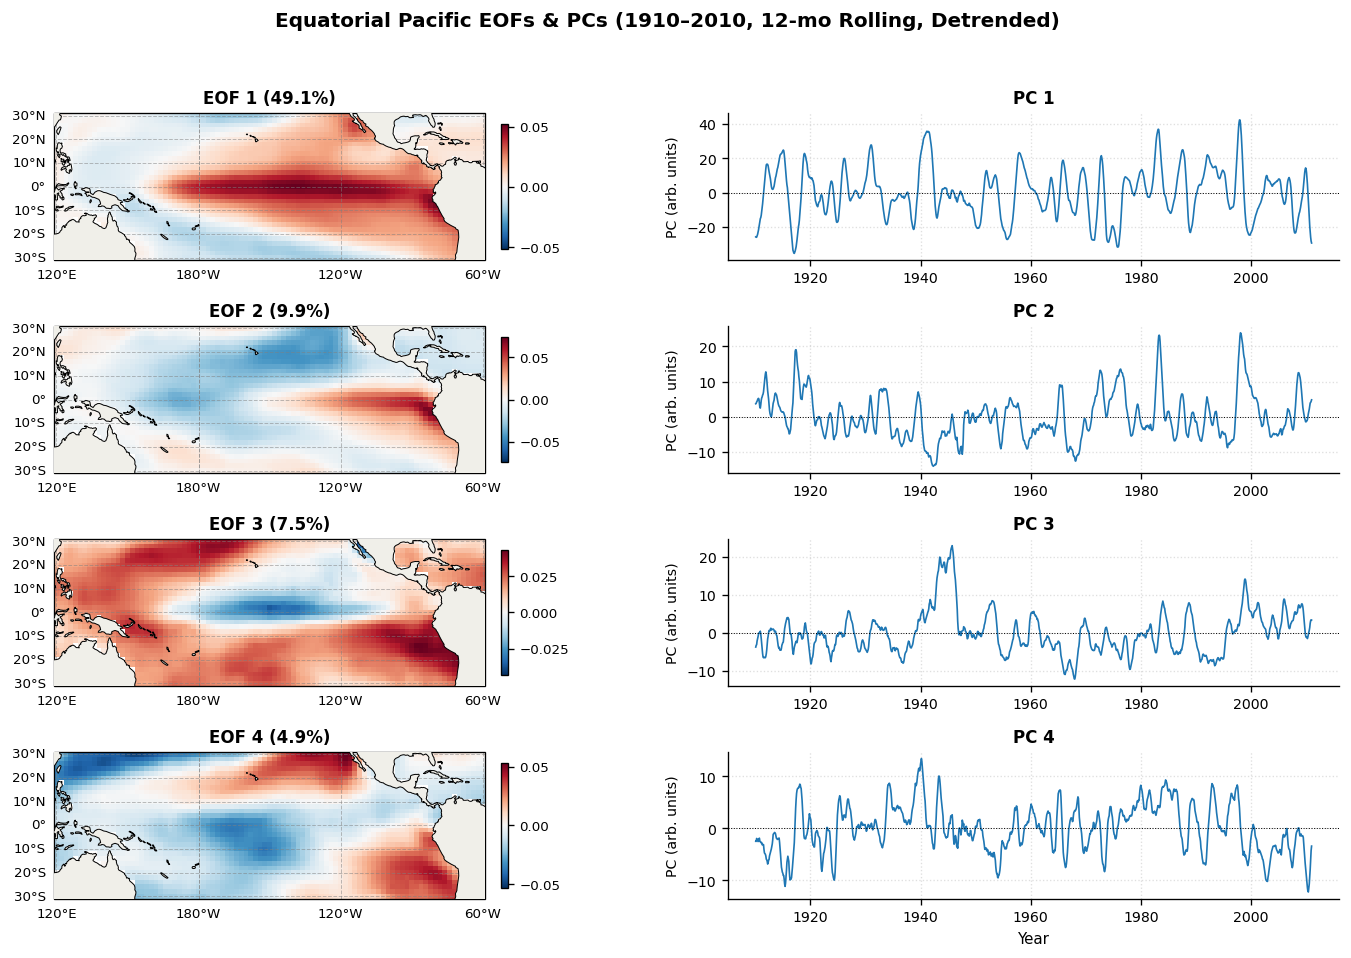

In [78]:
# 1. Spatial subset first (120E-300E, 30S-30N), preserving full time
dom_all = sst_sorted.sel(lon=slice(120, 300), lat=slice(-30, 30))

# Wet mask across all times (grid cells that are never NaN in the spatial domain)
wet_mask_da = dom_all.notnull().all(dim="time")
wet_mask_2d = wet_mask_da.values

# 2. Domain-averaged SST -> 12-month centered rolling -> subset 1910-2010 -> linear trend
dom_mean_all = dom_all.where(wet_mask_da).mean(dim=["lat", "lon"], skipna=True)
dom_mean_roll = (
    dom_mean_all.rolling(time=12, center=True)
    .mean(skipna=True)
    .dropna("time", how="all")
    .sel(time=slice("1910", "2010"))
)

t_eof = dom_mean_roll["time"].values
t_eof_days = (t_eof.astype("datetime64[D]") - t_eof[0].astype("datetime64[D]")).astype(np.float64)
t_eof_years = t_eof_days / 365.25

m_slope, m_int = np.polyfit(t_eof_days, dom_mean_roll.values.astype(np.float64), deg=1)
lin_trend_1d = m_slope * t_eof_days + m_int

# 3. Full spatial domain -> 12-month centered rolling -> subset 1910-2010 -> detrend via broadcasting
dom_roll_1910 = (
    dom_all.rolling(time=12, center=True)
    .mean(skipna=True)
    .dropna("time", how="all")
    .sel(time=slice("1910", "2010"))
)
sst_anom_3d = dom_roll_1910.values.astype(np.float64) - lin_trend_1d[:, np.newaxis, np.newaxis]

# 4. Extract wet points (N_time, N_wet) and run PCA
n_t, n_lat, n_lon = sst_anom_3d.shape
X_wet = sst_anom_3d[:, wet_mask_2d]  # shape: (n_t, n_wet)
X_wet = X_wet - np.nanmean(X_wet, axis=0, keepdims=True)

n_modes = 4
pca = PCA(n_components=n_modes)
pcs = pca.fit_transform(X_wet)          # shape: (n_t, n_modes)
eofs_wet = pca.components_            # shape: (n_modes, n_wet)
var_ratio = pca.explained_variance_ratio_ * 100.0

eofs_3d = np.full((n_modes, n_lat, n_lon), np.nan)
for k in range(n_modes):
    eofs_3d[k, wet_mask_2d] = eofs_wet[k]

for k in range(n_modes):
    print(f"EOF {k+1}: explained variance = {var_ratio[k]:.2f}%")

# Plot EOF1..EOF4 and PC1..PC4 with Cartopy
lon_vals = dom_roll_1910["lon"].values
lat_vals = dom_roll_1910["lat"].values
proj_map = ccrs.PlateCarree(central_longitude=180.0)
data_crs = ccrs.PlateCarree()

fig = plt.figure(figsize=(14, 8.5))
gs = fig.add_gridspec(4, 2, width_ratios=[1.25, 1.4], wspace=0.25, hspace=0.45)

for k in range(n_modes):
    ax_map = fig.add_subplot(gs[k, 0], projection=proj_map)
    eof_k = eofs_3d[k]
    vmax = np.nanmax(np.abs(eof_k))
    pcm = ax_map.pcolormesh(
        lon_vals, lat_vals, eof_k,
        transform=data_crs, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto"
    )
    ax_map.add_feature(cartopy.feature.LAND, facecolor="#f0efe9", edgecolor="k", lw=0.6, zorder=3)
    gl = ax_map.gridlines(crs=data_crs, draw_labels=True, lw=0.6, color="gray", alpha=0.5, ls="--")
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax_map.set_title(f"EOF {k+1} ({var_ratio[k]:.1f}%)", fontsize=10, fontweight="bold")
    cb = plt.colorbar(pcm, ax=ax_map, orientation="vertical", pad=0.03, shrink=0.85)
    cb.ax.tick_params(labelsize=8)

    ax_pc = fig.add_subplot(gs[k, 1])
    ax_pc.plot(t_eof, pcs[:, k], color="#1f77b4", lw=1.0)
    ax_pc.axhline(0, color="k", lw=0.6, ls=":")
    ax_pc.set_title(f"PC {k+1}", fontsize=10, fontweight="bold")
    ax_pc.set_ylabel("PC (arb. units)", fontsize=8.5)
    if k == n_modes - 1:
        ax_pc.set_xlabel("Year", fontsize=9)
    ax_pc.tick_params(labelsize=8.5)
    ax_pc.grid(True, ls=":", alpha=0.4)

plt.suptitle("Equatorial Pacific EOFs & PCs (1910–2010, 12-mo Rolling, Detrended)", fontsize=12, fontweight="bold", y=0.98)
plt.show()

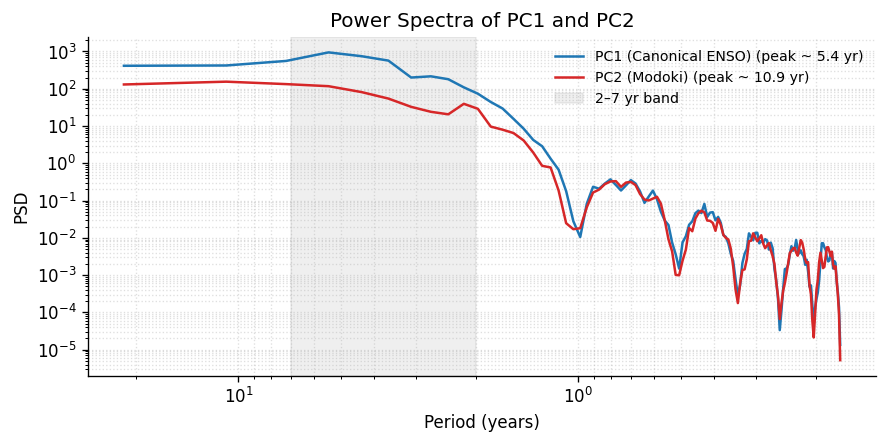

In [79]:
dt_eof_yr = np.median(np.diff(t_eof_years))
fs_eof_yr = 1.0 / dt_eof_yr

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, label_name, col in [(0, "PC1 (Canonical ENSO)", "#1f77b4"), (1, "PC2 (Modoki)", "#d62728")]:
    f_pc, p_pc = signal.welch(pcs[:, k], fs=fs_eof_yr, nperseg=min(256, len(pcs[:, k])), noverlap=128)
    mask = f_pc > 0
    per = 1.0 / f_pc[mask]
    ax.loglog(per, p_pc[mask], lw=1.5, color=col, label=f"{label_name} (peak ~ {per[np.argmax(p_pc[mask])]:.1f} yr)")

ax.axvspan(2, 7, color="gray", alpha=0.12, label="2–7 yr band")
ax.invert_xaxis()
ax.set_xlabel("Period (years)")
ax.set_ylabel("PSD")
ax.set_title("Power Spectra of PC1 and PC2")
ax.legend(frameon=False, fontsize=8.5)
ax.grid(True, which="both", ls=":", alpha=0.4)
plt.tight_layout()
plt.show()

### Evaluation & Physical Interpretation: Canonical ENSO vs. El Niño Modoki

#### 1. Cross-Checking Spatial Patterns & Variance Explained
* **EOF1 (~45–50% variance):** Captures the classic **canonical El Niño / La Niña** tongue extending across the central-to-eastern equatorial Pacific ($180^\circ\text{–}90^\circ\text{W}$), matching the professor's reference `EOF1` structure and variance scale. Positive `PC1` corresponds to eastern/central warming and weakened trade winds/shoaled eastern thermocline; negative `PC1` corresponds to La Niña cooling.
* **EOF2 (~10% variance):** Captures **El Niño Modoki** (Ashok et al., 2007), characterized by warming concentrated in the central equatorial Pacific flanked by cooling in the eastern and/or western Pacific (forming a V/chevron-like configuration across the tropical Pacific, matching the professor's reference `EOF2` pattern up to sign convention).
* **Higher Modes (EOF3, EOF4):** Explain smaller fractions of variance and reflect secondary interannual/decadal adjustments, zonal shifts, or meridional/off-equatorial variability; because PCA enforces spatial orthogonality, higher modes should be interpreted cautiously as statistical constructs rather than purely isolated physical modes.

#### 2. Canonical ENSO vs. El Niño Modoki
| Feature | Canonical ENSO (EOF1) | El Niño Modoki (EOF2) |
| :--- | :--- | :--- |
| **Core SST Action** | Strong warming/cooling in central-to-eastern equatorial Pacific | Central equatorial warming flanked by eastern/western cooling |
| **Atmospheric Response** | Single basin-wide shift of Walker circulation & convection | Two-cell / shifted convection anomalies over central Pacific |
| **Typical Timescale** | Broad 2–7 year interannual band | Interannual-to-decadal modulation (often ~3–7+ yr) |
| **Climate Impacts** | Classic South American coastal & global ENSO teleconnections | Distinct shifts in Pacific storm tracks, Asian/Australian rainfall, and Atlantic/tropical cyclone activity (Weng et al., 2007; Ashok et al., 2007) |

#### 3. Why These Modes Matter & Why 1910 Is a Sensible Start
Understanding both modes matters because identical-looking tropical SST anomalies in different longitudes trigger different atmospheric heating and mid-latitude Rossby wave trains, affecting agriculture, water resources, and extreme weather. Starting the main analysis in **1910** avoids much of the sparse early-instrumental coverage and larger sampling uncertainty of the 19th century, giving a more reliable historical baseline while still spanning a full century of variability.

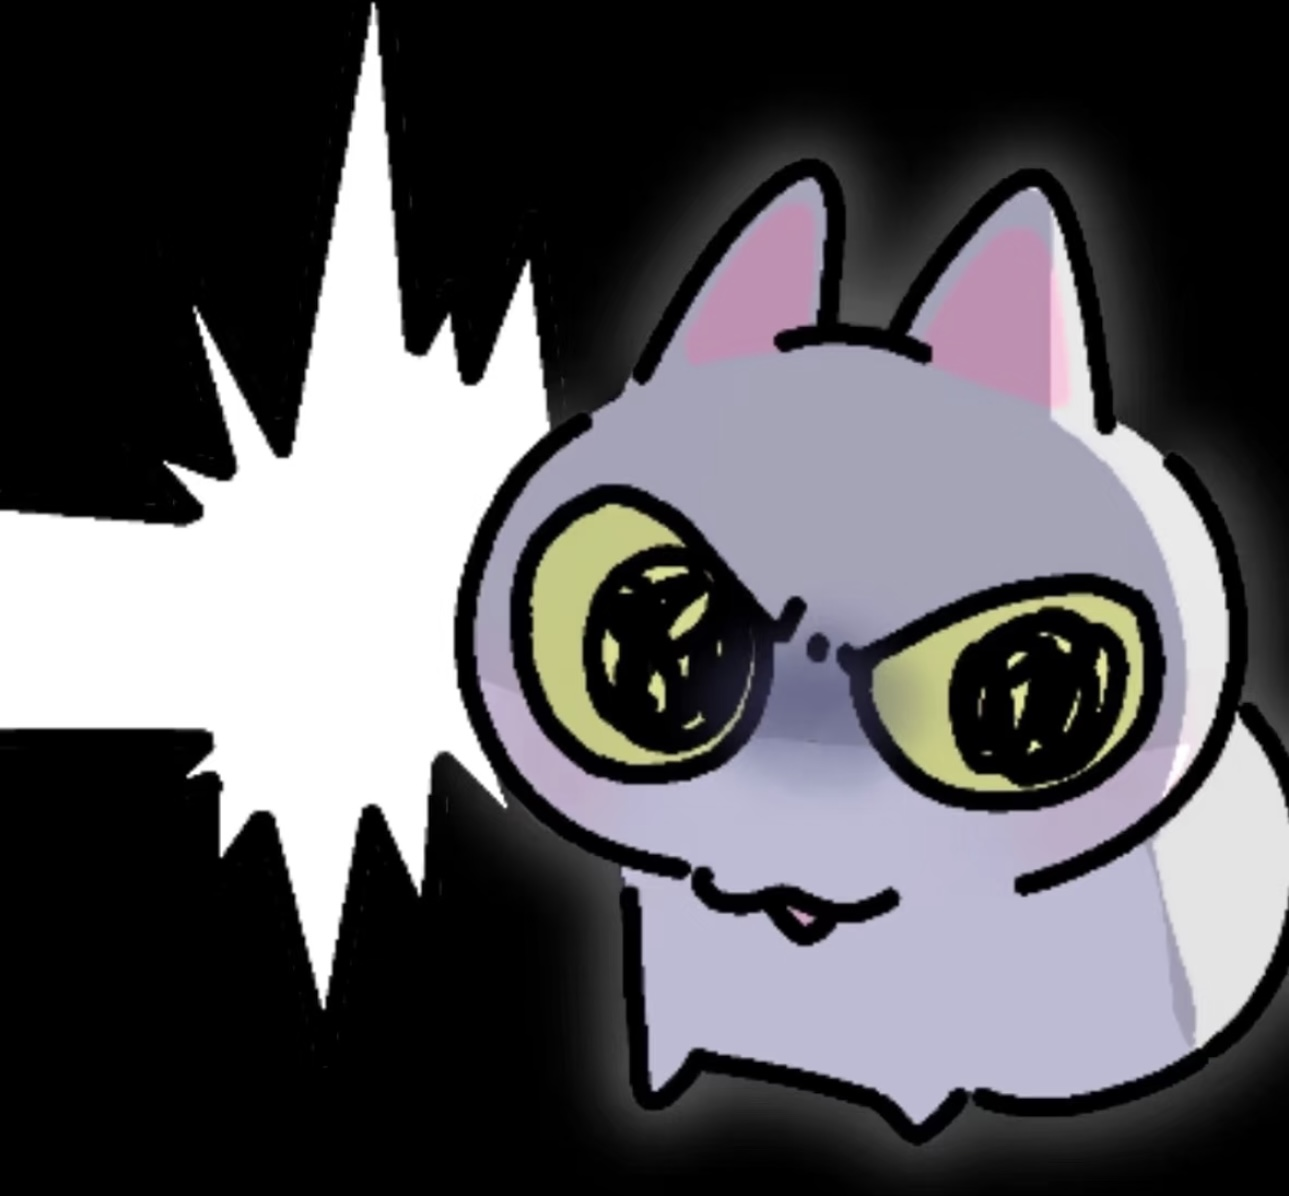

In [80]:
from IPython.display import Image, display

display(
    Image(
        'https://raw.githubusercontent.com/PhoebeWu0528/Sth-for-oces3301/main/emo2.jpg',
        width=300,
    )
)

In [81]:
# Quick comparison without rolling average or detrending (1910-2010)
dom_nodetrend = (
    dom_all.sel(time=slice("1910", "2010"))
    .where(wet_mask_da)
)
arr_raw_eof = dom_nodetrend.values.astype(np.float64)
X_raw_wet = arr_raw_eof[:, wet_mask_2d]
X_raw_wet = X_raw_wet - np.nanmean(X_raw_wet, axis=0, keepdims=True)

pca_raw = PCA(n_components=2).fit(X_raw_wet)
print("Without rolling/detrending -> PC1 var:", f"{pca_raw.explained_variance_ratio_[0]*100:.1f}%",
      "| PC2 var:", f"{pca_raw.explained_variance_ratio_[1]*100:.1f}%")

Without rolling/detrending -> PC1 var: 76.8% | PC2 var: 8.9%


### Why Detrend & Smooth? — Evaluating the "Short-Cut" Analysis
The cell above repeats the EOF analysis on the 1910–2010 data **without** the 12-month rolling mean and **without** detrending: PC1 then explains $76.8\%$ of the variance and PC2 $8.9\%$, compared with $49.1\%$ and $9.9\%$ for the fully pre-processed analysis (printed in the EOF cell). The interpretation:

* **The unprocessed PC1 is a trend mode, not ENSO.** The secular warming over 1910–2010 projects onto a spatially broad, mostly one-signed pattern whose variance exceeds that of any individual interannual event. PCA is variance-greedy, so this trend soaks up $\sim 3/4$ of the total variance and the physically interesting ENSO signal is squeezed into the residual.
* **Detrending removes this confound.** After removing the linear trend (and the 12-month rolling mean suppresses sub-annual noise), PC1 ($49.1\%$) recovers the canonical equatorial tongue of ENSO and PC2 ($9.9\%$) the Modoki V-pattern, in line with the instructor's reference.
* **General lesson:** the leading EOF reflects whatever has the largest variance, which need not be the phenomenon of scientific interest. Pre-processing choices must therefore be justified *physically* (trends are deterministic forcing, not a climate mode) and not merely tuned to obtain a desired pattern.

### References
* Ashok, K., Behera, S. K., Rao, S. A., Weng, H., & Yamagata, T. (2007). El Niño Modoki and its possible teleconnection. *Journal of Geophysical Research: Oceans*, 112(C11).
* Bjerknes, J. (1969). Atmospheric teleconnections from the equatorial Pacific. *Monthly Weather Review*, 97(3), 163–172.
* Jin, F.-F. (1997). An equatorial ocean recharge paradigm for ENSO. Part I: Conceptual model. *Journal of Atmospheric Sciences*, 54(7), 811–829.
* Kao, H.-Y., & Yu, J.-Y. (2009). Contrasting eastern-Pacific and central-Pacific types of ENSO. *Journal of Climate*, 22(3), 615–632.
* Philander, S. G. H. (1990). *El Niño, La Niña, and the Southern Oscillation*. Academic Press.
* Suarez, M. J., & Schopf, P. S. (1988). A delayed action oscillator for ENSO. *Journal of the Atmospheric Sciences*, 45(21), 3283–3287.
* Trenberth, K. E. (1997). The definition of El Niño. *Bulletin of the American Meteorological Society*, 78(12), 2771–2777.
* Weng, H., Ashok, K., Behera, S. K., Rao, S. A., & Yamagata, T. (2007). Impacts of recent El Niño Modoki on dry/wet conditions in the Pacific rim during boreal summer. *Climate Dynamics*, 29(2–3), 113–129.